# Case Study 1: E-commerce Conversion

**Question:** which sessions are associated with purchase completion, and where does the funnel drop?

- Data: session_id, channel, device, pages_viewed, cart_value, time_on_site, purchased.
- EDA: conversion by channel/device, missingness, cart-value distribution, funnel stage counts.
- Features: pages_per_minute, cart_value_bucket, session_hour; ensure features exist before prediction time.
- Deliverable: evidence-backed recommendations, limitations and a proposed offline evaluation plan.

This notebook uses a reproducible **synthetic dataset of 5,000 sessions** because no real session CSV was supplied. 

**Target:** purchased (1 = purchase completed in the outcome window; 0 = no purchase).

## tl;dr

In this simulation, overall purchase conversion is **23.88%**. Direct traffic has the highest channel conversion (**28.15%**) and Social the lowest (**16.62%**); Desktop converts at **28.02%** compared with Mobile at **21.02%**. About **65.28%** of sessions show cart activity, and **63.42%** of cart sessions do not complete a purchase.

On the chronological test set, balanced Logistic Regression reaches **67.6% accuracy**, **74.34% balanced accuracy**, **86.43% purchase recall**, and **59.79% PR-AUC**. The majority baseline has **77.9% accuracy** but only **50% balanced accuracy**, illustrating why accuracy alone is insufficient. These are results from synthetic data and must not be interpreted as real business performance.


## Context & Methods

### Business question
Which session characteristics are associated with purchase completion, and at which observable funnel transition do sessions drop off?

### Dataset grain and prediction point
Each row represents one website session. The simulated prediction point occurs after an initial browsing snapshot. `pages_viewed`, `cart_value`, and `time_on_site` describe what is known **at that snapshot**. `purchased` records whether a purchase occurs in the following 30-minute outcome window.

### Key assumptions
- The dataset is synthetic and generated with a fixed random seed.
- Cart activity is represented by `cart_value > 0`.
- The funnel is simplified to session → cart activity → purchase. The data does not contain checkout-start or payment-step events.
- `session_start_time` is available at the prediction point and is used to derive `session_hour`.
- We use a chronological 80/20 split for the offline model evaluation to better approximate future prediction.
- Associations in this synthetic dataset do not establish causation.

## Data

### 1. Imports and reproducibility

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, average_precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
N_SESSIONS = 5000

plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

### 2. Generate the synthetic session dataset

The data generator creates realistic-looking variation in channels, devices, browsing activity, cart values, and session start times. Purchase probability is based only on variables available at the prediction snapshot.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)

session_id = np.arange(1001, 1001 + N_SESSIONS)

channel = rng.choice(
    ["Organic", "Paid", "Social", "Referral", "Direct"],
    size=N_SESSIONS,
    p=[0.30, 0.25, 0.15, 0.10, 0.20]
)

device = rng.choice(
    ["Mobile", "Desktop", "Tablet"],
    size=N_SESSIONS,
    p=[0.55, 0.35, 0.10]
)

# Snapshot activity: these values are known at prediction time.
pages_viewed = rng.poisson(lam=5, size=N_SESSIONS) + 1
time_on_site = rng.gamma(shape=2.5, scale=100, size=N_SESSIONS).astype(int)

# A cart is present for about 65% of sessions.
cart_added = rng.binomial(1, 0.65, size=N_SESSIONS)
cart_value = np.where(
    cart_added == 1,
    rng.gamma(shape=2.5, scale=400, size=N_SESSIONS),
    0.0
)
cart_value = np.round(cart_value, 2)

channel_effect = pd.Series(channel).map({
    "Organic": 0.45,
    "Paid": 0.10,
    "Social": -0.35,
    "Referral": 0.25,
    "Direct": 0.50
}).to_numpy()

device_effect = pd.Series(device).map({
    "Mobile": -0.20,
    "Desktop": 0.35,
    "Tablet": 0.05
}).to_numpy()

# Synthetic purchase probability in the 30 minutes after the snapshot.
logit = (
    -2.6
    + 0.12 * pages_viewed
    + 0.0015 * time_on_site
    + 0.0007 * cart_value
    + channel_effect
    + device_effect
)
purchase_probability = 1 / (1 + np.exp(-logit))

# A purchase requires a cart in this simplified scenario.
purchase_probability = purchase_probability * cart_added
purchased = rng.binomial(1, purchase_probability)

# Session starts are distributed over six months.
start_seconds = rng.integers(
    0,
    int((pd.Timestamp("2026-07-01") - pd.Timestamp("2026-01-01")).total_seconds()),
    size=N_SESSIONS
)
session_start_time = pd.Timestamp("2026-01-01") + pd.to_timedelta(start_seconds, unit="s")

df = pd.DataFrame({
    "session_id": session_id,
    "channel": channel,
    "device": device,
    "pages_viewed": pages_viewed.astype(float),
    "cart_value": cart_value,
    "time_on_site": time_on_site.astype(float),
    "session_start_time": session_start_time,
    "purchased": purchased.astype(int)
})

# Introduce a small amount of missingness in observed activity fields.
# Cart value is retained so the simplified funnel remains fully observable.
missing_pages_idx = rng.choice(df.index, size=50, replace=False)
missing_time_idx = rng.choice(df.index, size=50, replace=False)
df.loc[missing_pages_idx, "pages_viewed"] = np.nan
df.loc[missing_time_idx, "time_on_site"] = np.nan

df.to_csv("ecommerce_sessions_synthetic.csv", index=False)

print("Synthetic dataset created and saved.")
print("Shape:", df.shape)
display(df.head())

Synthetic dataset created and saved.
Shape: (5000, 8)


,session_id,channel,device,pages_viewed,cart_value,time_on_site,session_start_time,purchased
0,1001,Referral,Mobile,4.0,2071.42,210.0,2026-05-19 03:15:45,1
1,1002,Paid,Desktop,5.0,0.00,154.0,2026-06-24 18:28:19,0
2,1003,Direct,Desktop,4.0,0.00,120.0,2026-02-08 06:51:48,0
3,1004,Social,Mobile,6.0,0.00,121.0,2026-03-12 06:48:51,0
4,1005,Organic,Mobile,6.0,0.00,349.0,2026-05-08 12:09:49,0


### 3. Validate the data
Check column names, data types, duplicates, target values, and basic ranges before analysis.

In [ ]:
print("Columns:", df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

Columns: ['session_id', 'channel', 'device', 'pages_viewed', 'cart_value', 'time_on_site', 'session_start_time', 'purchased']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   session_id          5000 non-null   int64         
 1   channel             5000 non-null   object        
 2   device              5000 non-null   object        
 3   pages_viewed        4950 non-null   float64       
 4   cart_value          5000 non-null   float64       
 5   time_on_site        4950 non-null   float64       
 6   session_start_time  5000 non-null   datetime64[ns]
 7   purchased           5000 non-null   int64         
dtypes: datetime64[ns](1), float64(3), int64(2), object(2)
memory usage: 312.6+ KB


In [5]:
print("\nExact duplicate rows:", df.duplicated().sum())
print("Duplicate session IDs:", df["session_id"].duplicated().sum())

print("\nTarget values:")
print(df["purchased"].value_counts().sort_index())


Exact duplicate rows: 0
Duplicate session IDs: 0

Target values:
purchased
0    3806
1    1194
Name: count, dtype: int64


In [6]:
assert df["session_id"].is_unique
assert set(df["purchased"].dropna().unique()).issubset({0, 1})
assert (df["pages_viewed"].dropna() >= 0).all()
assert (df["cart_value"].dropna() >= 0).all()
assert (df["time_on_site"].dropna() >= 0).all()

## Results

## Task A – Exploratory Data Analysis

### 4. Dataset shape, missingness, and descriptive statistics

In [7]:
print("Dataset shape (rows, columns):", df.shape)

Dataset shape (rows, columns): (5000, 8)


In [9]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

display(missing_summary)

,missing_count,missing_percent
pages_viewed,50,1.0
time_on_site,50,1.0
session_id,0,0.0
channel,0,0.0
device,0,0.0
cart_value,0,0.0
session_start_time,0,0.0
purchased,0,0.0


In [11]:
display(df[["pages_viewed", "cart_value", "time_on_site"]].describe())

,pages_viewed,cart_value,time_on_site
count,4950.000000,5000.000000,4950.000000
mean,6.034747,649.555834,244.943434
std,2.282973,701.010796,153.961555
min,1.000000,0.000000,2.000000
25%,4.000000,0.000000,131.000000
50%,6.000000,504.285000,212.000000
75%,7.000000,1035.335000,327.000000
max,16.000000,5162.750000,1430.000000


### 5. Conversion by channel and device

Conversion rate is the share of sessions in a group with `purchased = 1`. 

Always read it with the group size; a high rate from a small group may be less stable.

In [18]:
channel_summary = (
    df.groupby("channel", observed=True)
      .agg(sessions=("session_id", "count"),
           purchases=("purchased", "sum"),
           conversion_rate=("purchased", "mean"))
      .assign(conversion_rate_pct=lambda x: x["conversion_rate"] * 100).round(2)
      .sort_values("conversion_rate", ascending=False)
)

device_summary = (
    df.groupby("device", observed=True)
      .agg(sessions=("session_id", "count"),
           purchases=("purchased", "sum"),
           conversion_rate=("purchased", "mean"))
      .assign(conversion_rate_pct=lambda x: x["conversion_rate"] * 100).round(2)
      .sort_values("conversion_rate", ascending=False)
)

print("Conversion by channel:")
display(channel_summary[["sessions", "purchases", "conversion_rate_pct"]])

print("Conversion by device:")
display(device_summary[["sessions", "purchases", "conversion_rate_pct"]])

Conversion by channel:


,sessions,purchases,conversion_rate_pct
channel,,,
Direct,984,277,28.15
Organic,1541,415,26.93
Referral,488,114,23.36
Paid,1253,266,21.23
Social,734,122,16.62


Conversion by device:


,sessions,purchases,conversion_rate_pct
device,,,
Desktop,1777,498,28.02
Tablet,492,122,24.80
Mobile,2731,574,21.02


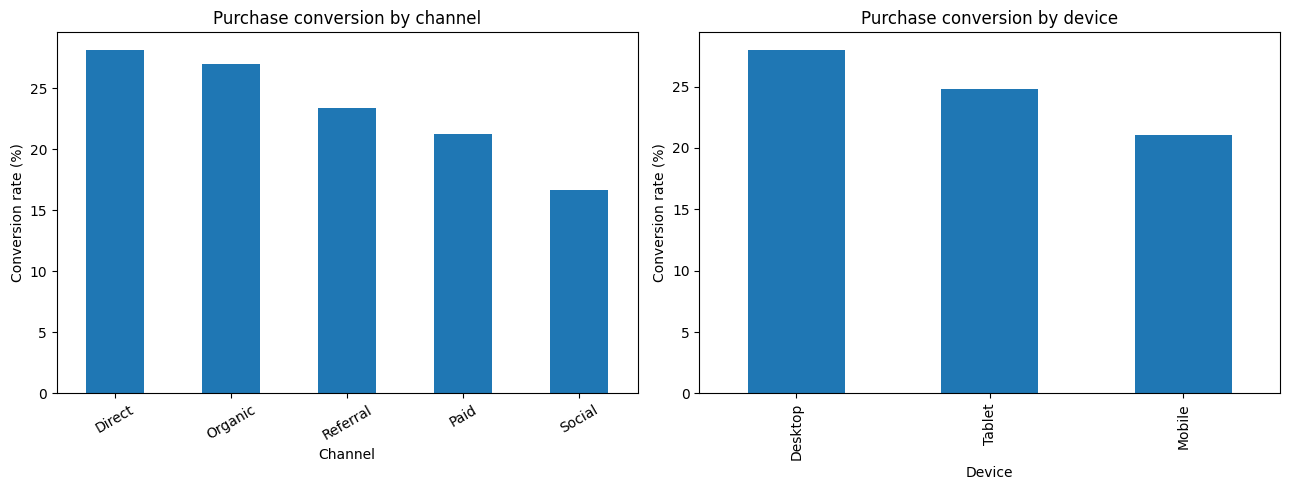

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

channel_summary["conversion_rate_pct"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Purchase conversion by channel")
axes[0].set_xlabel("Channel")
axes[0].set_ylabel("Conversion rate (%)")
axes[0].tick_params(axis="x", rotation=30)

device_summary["conversion_rate_pct"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Purchase conversion by device")
axes[1].set_xlabel("Device")
axes[1].set_ylabel("Conversion rate (%)")

plt.tight_layout()
plt.show()

### 6. Cart-value distribution
Zero values indicate sessions with no cart activity. The distribution is expected to be right-skewed because cart values cannot be negative and a smaller number of sessions may have larger baskets.

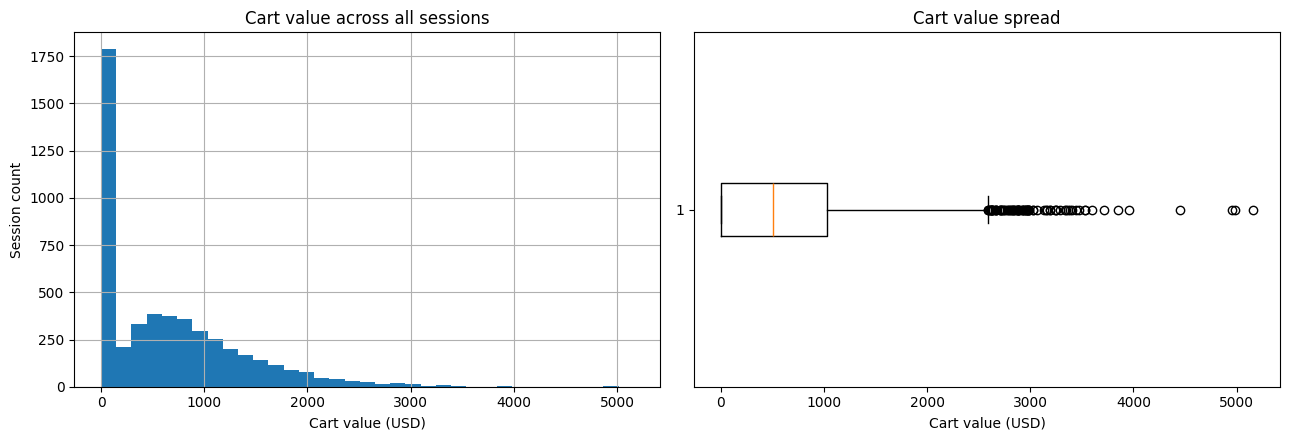

Cart value median: 504.28
Cart value 90th percentile: 1617.7
Sessions with zero cart value: 1736


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

df["cart_value"].dropna().hist(bins=35, ax=axes[0])
axes[0].set_title("Cart value across all sessions")
axes[0].set_xlabel("Cart value (USD)")
axes[0].set_ylabel("Session count")

axes[1].boxplot(df["cart_value"].dropna(), vert=False)
axes[1].set_title("Cart value spread")
axes[1].set_xlabel("Cart value (USD)")

plt.tight_layout()
plt.show()

print("Cart value median:", round(df["cart_value"].median(), 2))
print("Cart value 90th percentile:", round(df["cart_value"].quantile(0.90), 2))
print("Sessions with zero cart value:", int((df["cart_value"] == 0).sum()))

### 7. Simplified conversion funnel
The available fields support 3 observable stages: 
- all sessions
- sessions with a positive cart value
- completed purchases. 

There are no explicit checkout-start or payment events, so this is not a full checkout funnel.

In [9]:
total_sessions = len(df)
cart_sessions = int((df["cart_value"] > 0).sum())
purchase_sessions = int(df["purchased"].sum())

funnel = pd.DataFrame({
    "stage": ["Website sessions", "Cart activity", "Purchase completed"],
    "sessions": [total_sessions, cart_sessions, purchase_sessions]
})

funnel["share_of_all_sessions_pct"] = (
    funnel["sessions"] / total_sessions * 100
).round(2)

print("Funnel counts:")
display(funnel)

session_to_cart_dropoff = (1 - cart_sessions / total_sessions) * 100
cart_to_purchase_dropoff = (
    (1 - purchase_sessions / cart_sessions) * 100
    if cart_sessions else np.nan
)

print(f"Session → cart drop-off: {session_to_cart_dropoff:.2f}%")
print(f"Cart → purchase drop-off: {cart_to_purchase_dropoff:.2f}%")

Funnel counts:


,stage,sessions,share_of_all_sessions_pct
0,Website sessions,5000,100.00
1,Cart activity,3264,65.28
2,Purchase completed,1194,23.88


Session → cart drop-off: 34.72%
Cart → purchase drop-off: 63.42%


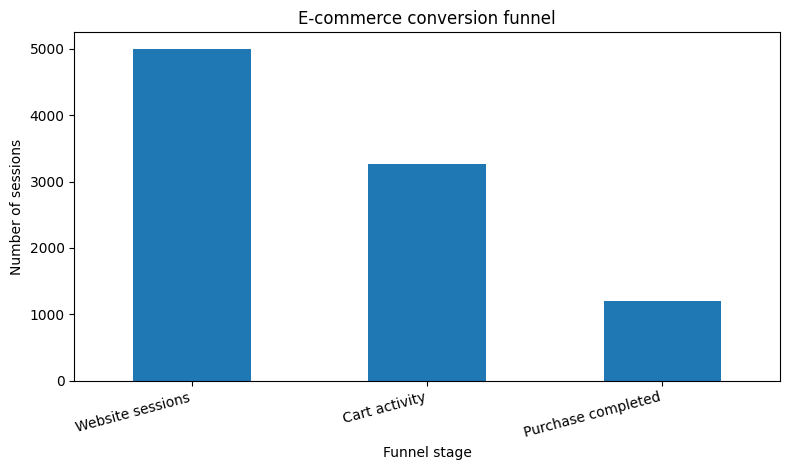

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.8))
funnel.plot(kind="bar", x="stage", y="sessions", legend=False, ax=ax)
ax.set_title("E-commerce conversion funnel")
ax.set_xlabel("Funnel stage")
ax.set_ylabel("Number of sessions")
ax.ticklabel_format(style="plain", axis="y")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## Task B – Feature Engineering

### 8. Create features available at the prediction snapshot

- `pages_per_minute`: browsing intensity at the snapshot.
- `cart_value_bucket`: no cart, low, medium, or high cart value.
- `session_hour`: hour when the session started.

The cart thresholds below are illustrative business bands. Change them if the observed distribution suggests better cutoffs.

In [11]:
# Pages per minute. time_on_site is measured in seconds at the snapshot.
minutes_on_site = df["time_on_site"] / 60
df["pages_per_minute"] = (
    df["pages_viewed"] / minutes_on_site.replace(0, np.nan)
)
df["pages_per_minute"] = df["pages_per_minute"].replace(
    [np.inf, -np.inf], np.nan
)

# Fixed, interpretable cart-value bands.
df["cart_value_bucket"] = pd.cut(
    df["cart_value"],
    bins=[-0.01, 0, 500, 1500, np.inf],
    labels=["No cart", "Low", "Medium", "High"],
    include_lowest=True
)

# Extract hour from session start timestamp.
df["session_start_time"] = pd.to_datetime(df["session_start_time"])
df["session_hour"] = df["session_start_time"].dt.hour

engineered_columns = [
    "pages_per_minute", "cart_value_bucket", "session_hour"
]
display(df[["session_id"] + engineered_columns].head(10))
print("\nEngineered feature missingness:")
display(df[engineered_columns].isna().sum().to_frame("missing_count"))

,session_id,pages_per_minute,cart_value_bucket,session_hour
0,1001,1.142857,High,3
1,1002,1.948052,No cart,18
2,1003,2.000000,No cart,6
3,1004,2.975207,No cart,6
4,1005,1.031519,No cart,12
5,1006,1.153846,Medium,7
6,1007,4.379562,Low,5
7,1008,1.888112,High,7
8,1009,0.571429,High,15
9,1010,2.045455,No cart,12



Engineered feature missingness:


,missing_count
pages_per_minute,100
cart_value_bucket,0
session_hour,0


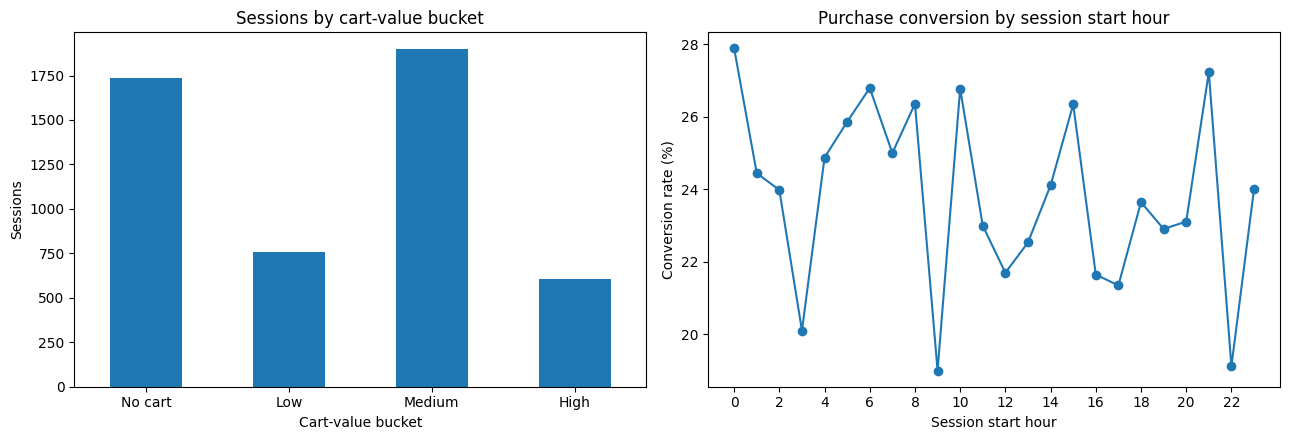

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

df["cart_value_bucket"].value_counts().reindex(
    ["No cart", "Low", "Medium", "High"]
).plot(kind="bar", ax=axes[0])
axes[0].set_title("Sessions by cart-value bucket")
axes[0].set_xlabel("Cart-value bucket")
axes[0].set_ylabel("Sessions")
axes[0].tick_params(axis="x", rotation=0)

hourly_conversion = (
    df.groupby("session_hour", observed=True)["purchased"].mean() * 100
)
hourly_conversion.plot(kind="line", marker="o", ax=axes[1])
axes[1].set_title("Purchase conversion by session start hour")
axes[1].set_xlabel("Session start hour")
axes[1].set_ylabel("Conversion rate (%)")
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

### 9. Check prediction-time availability and leakage

The synthetic data is deliberately defined around a prediction snapshot: the activity fields are observed at that snapshot, while `purchased` describes the following 30 minutes. This makes the listed predictors available before the target outcome.

In a real analytics export, verify that `pages_viewed`, `cart_value`, and `time_on_site` are snapshot values—not final session totals recorded after purchase. If they are final totals, they must not be used to predict an earlier purchase.

In [13]:
feature_availability = pd.DataFrame({
    "feature": [
        "channel", "device", "pages_viewed", "cart_value",
        "time_on_site", "pages_per_minute",
        "cart_value_bucket", "session_hour"
    ],
    "available_at_prediction_snapshot": [True] * 8,
    "reason": [
        "Traffic source known for the session",
        "Device known for the session",
        "Page count observed up to snapshot",
        "Cart value observed up to snapshot",
        "Elapsed time observed up to snapshot",
        "Calculated from snapshot page count and elapsed time",
        "Calculated from snapshot cart value",
        "Derived from session start timestamp"
    ]
})
display(feature_availability)

,feature,available_at_prediction_snapshot,reason
0,channel,True,Traffic source known for the session
1,device,True,Device known for the session
2,pages_viewed,True,Page count observed up to snapshot
3,cart_value,True,Cart value observed up to snapshot
4,time_on_site,True,Elapsed time observed up to snapshot
5,pages_per_minute,True,Calculated from snapshot page count and elapse...
6,cart_value_bucket,True,Calculated from snapshot cart value
7,session_hour,True,Derived from session start timestamp


## Task C – Offline Evaluation Plan and Model Comparison

### 10. Define the prediction task

Predict whether a session will complete a purchase in the 30 minutes after the snapshot. Use a chronological split: earlier sessions for training and later sessions for testing.

In [14]:
# Sort chronologically before splitting.
model_df = df.sort_values("session_start_time").reset_index(drop=True)

split_index = int(len(model_df) * 0.80)
train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

feature_columns = [
    "channel", "device", "pages_viewed", "cart_value",
    "time_on_site", "pages_per_minute",
    "cart_value_bucket", "session_hour"
]

target_column = "purchased"

X_train = train_df[feature_columns]
y_train = train_df[target_column]
X_test = test_df[feature_columns]
y_test = test_df[target_column]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", train_df["session_start_time"].min(), "to",
      train_df["session_start_time"].max())
print("Testing period:", test_df["session_start_time"].min(), "to",
      test_df["session_start_time"].max())
print("\nTraining purchase rate:", round(y_train.mean() * 100, 2), "%")
print("Testing purchase rate:", round(y_test.mean() * 100, 2), "%")

Training rows: 4000
Testing rows: 1000
Training period: 2026-01-01 00:40:53 to 2026-05-27 01:30:17
Testing period: 2026-05-27 01:51:33 to 2026-06-30 23:12:48

Training purchase rate: 24.32 %
Testing purchase rate: 22.1 %


### 11. Build leakage-safe preprocessing

Numeric missing values are imputed with the training median and standardized. Categorical missing values are imputed with the training mode and one-hot encoded. The preprocessing is fitted only on the training set through the Pipeline.

In [15]:
numeric_features = [
    "pages_viewed", "cart_value", "time_on_site",
    "pages_per_minute", "session_hour"
]
categorical_features = [
    "channel", "device", "cart_value_bucket"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

### 12. Train a majority-class baseline and Logistic Regression

In [16]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

logistic_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
logistic_model.fit(X_train, y_train)
logistic_pred = logistic_model.predict(X_test)
logistic_probability = logistic_model.predict_proba(X_test)[:, 1]

def evaluate_model(name, y_true, y_pred, y_score=None):
    result = {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0)
    }
    if y_score is not None:
        result["pr_auc"] = average_precision_score(y_true, y_score)
    else:
        result["pr_auc"] = np.nan
    return result

results = pd.DataFrame([
    evaluate_model("Majority-class baseline", y_test, baseline_pred),
    evaluate_model("Logistic Regression (balanced)", y_test, logistic_pred, logistic_probability)
]).set_index("model")

display((results * 100).round(2))

,accuracy,balanced_accuracy,precision,recall,f1,pr_auc
model,,,,,,
Majority-class baseline,77.9,50.00,0.00,0.00,0.00,NaN
Logistic Regression (balanced),67.6,74.34,39.38,86.43,54.11,59.79


### 13. Confusion matrix and classification report
The confusion matrix shows how many actual purchasers and non-purchasers were correctly or incorrectly classified. The positive class is `purchased = 1`.

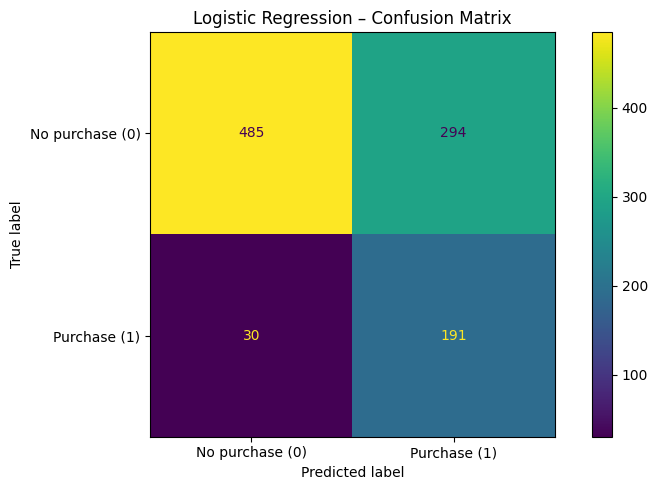

              precision    recall  f1-score   support

 No purchase       0.94      0.62      0.75       779
    Purchase       0.39      0.86      0.54       221

    accuracy                           0.68      1000
   macro avg       0.67      0.74      0.65      1000
weighted avg       0.82      0.68      0.70      1000



In [17]:
cm = confusion_matrix(y_test, logistic_pred, labels=[0, 1])

display_labels = ["No purchase (0)", "Purchase (1)"]
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)
disp.plot(values_format="d")
plt.title("Logistic Regression – Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test, logistic_pred,
    target_names=["No purchase", "Purchase"],
    zero_division=0
))

### 14. Compare model metrics
For purchase prediction, recall can matter when the goal is to identify likely purchasers for timely assistance, while precision matters when outreach or incentives are costly. PR-AUC summarizes the precision-recall trade-off across thresholds.

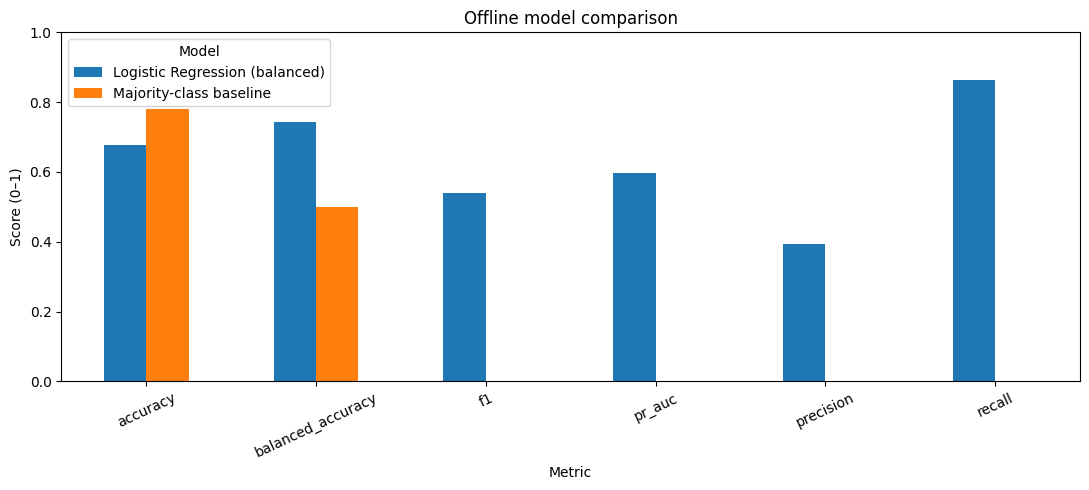

In [18]:
metrics_to_plot = ["accuracy", "balanced_accuracy", "precision", "recall", "f1", "pr_auc"]
plot_results = results[metrics_to_plot].reset_index().melt(
    id_vars="model", var_name="metric", value_name="score"
)

fig, ax = plt.subplots(figsize=(11, 5))
plot_results.pivot(index="metric", columns="model", values="score").plot(
    kind="bar", ax=ax
)
ax.set_title("Offline model comparison")
ax.set_xlabel("Metric")
ax.set_ylabel("Score (0–1)")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Model", loc="best")
plt.tight_layout()
plt.show()

## Takeaways

### 15. Evidence-backed findings
The following cell generates findings directly from the executed synthetic data. Treat them as findings about this simulation only—not real customer behaviour.

In [19]:
best_channel = channel_summary["conversion_rate_pct"].idxmax()
best_channel_rate = channel_summary.loc[best_channel, "conversion_rate_pct"]
worst_channel = channel_summary["conversion_rate_pct"].idxmin()
worst_channel_rate = channel_summary.loc[worst_channel, "conversion_rate_pct"]

best_device = device_summary["conversion_rate_pct"].idxmax()
best_device_rate = device_summary.loc[best_device, "conversion_rate_pct"]
worst_device = device_summary["conversion_rate_pct"].idxmin()
worst_device_rate = device_summary.loc[worst_device, "conversion_rate_pct"]

purchase_rate = df["purchased"].mean() * 100
cart_rate = cart_sessions / total_sessions * 100
cart_purchase_rate = purchase_sessions / cart_sessions * 100 if cart_sessions else np.nan

print("SYNTHETIC DATA FINDINGS")
print(f"1. Overall purchase conversion: {purchase_rate:.2f}% of sessions.")
print(f"2. Highest-converting channel: {best_channel} ({best_channel_rate:.2f}%); "
      f"lowest: {worst_channel} ({worst_channel_rate:.2f}%).")
print(f"3. Highest-converting device: {best_device} ({best_device_rate:.2f}%); "
      f"lowest: {worst_device} ({worst_device_rate:.2f}%).")
print(f"4. {cart_rate:.2f}% of sessions show cart activity; "
      f"{cart_purchase_rate:.2f}% of cart sessions complete a purchase.")
print(f"5. Session-to-cart drop-off: {session_to_cart_dropoff:.2f}%; "
      f"cart-to-purchase drop-off: {cart_to_purchase_dropoff:.2f}%.")

SYNTHETIC DATA FINDINGS
1. Overall purchase conversion: 23.88% of sessions.
2. Highest-converting channel: Direct (28.15%); lowest: Social (16.62%).
3. Highest-converting device: Desktop (28.02%); lowest: Mobile (21.02%).
4. 65.28% of sessions show cart activity; 36.58% of cart sessions complete a purchase.
5. Session-to-cart drop-off: 34.72%; cart-to-purchase drop-off: 63.42%.


### 16. Recommendations

Use the computed findings above to prioritize recommendations. The suggestions below are hypotheses to test, not proven causal explanations:

- Review the landing pages and traffic quality of lower-converting channels before changing channel budgets.
- Investigate mobile checkout usability if mobile conversion is materially lower than desktop conversion.
- If cart-to-purchase drop-off is high, inspect checkout steps, shipping fees, payment failures, and unexpected costs using event-level instrumentation.
- Use cart-value and browsing-intensity segments to design experiments, rather than assuming higher values or faster browsing cause purchase.
- Run controlled A/B tests before rolling out major checkout or marketing changes.

### 17. Limitations

1. **Synthetic data:** Results are generated from assumptions and cannot support real business decisions.
2. **Simplified funnel:** No checkout-start, payment-attempt, or payment-success events are available.
3. **Session-level grain:** The data does not identify repeat visitors or connect multiple sessions to one customer.
4. **Prediction snapshot:** In real data, verify that browsing and cart fields are captured before the outcome. Final session totals would leak future information.
5. **Unobserved factors:** Price, inventory, shipping cost, page performance, promotions, and payment errors are not represented.
6. **No causal inference:** Segment conversion differences are associations, not proof that channel or device causes purchase.
7. **Model evaluation:** A single chronological holdout is a first offline check. A production plan should use multiple rolling time windows, calibration checks, threshold selection, and monitoring for drift.

### 18. Proposed offline evaluation plan

1. Capture a timestamped feature snapshot at a defined decision point (for example, after five minutes of a session).
2. Define the label as purchase completion within the next 30 minutes.
3. Exclude sessions whose outcome window is incomplete.
4. Train on earlier time periods and test on later periods; repeat with rolling time-based validation.
5. Compare a majority-class baseline with Logistic Regression and a tree-based model.
6. Report precision, recall, F1, PR-AUC, balanced accuracy, and calibration.
7. Select a decision threshold based on the business cost of missed purchases versus unnecessary interventions.
8. Validate recommendations through an A/B test before deployment.

### 19. Final conclusion

This case study demonstrates how EDA identifies purchase patterns and funnel drop-offs, feature engineering creates useful session-level predictors, and offline evaluation compares a simple baseline with a classification model. Because the data is synthetic, all numerical findings are illustrative. A real deployment requires timestamped pre-outcome features, richer funnel events, and validation on future real sessions.